# 05 · Comparing all five methods

Collects the results of notebooks 01–04 into one table with confidence intervals and shows every person's decision under every method.

*Data: Gao et al. (2014), public Dryad release, doi:10.5061/dryad.2qc64. Own analysis; the plan (folds, training task, decision rule) was fixed before results.*

In [1]:
import os, json, numpy as np, matplotlib.pyplot as plt
# Point GAO_DIR at the "14 electrodes-30 subjects" folder of the Dryad release; GKT_WORK holds all derived files
os.environ.setdefault("GAO_DIR", "./data/14 electrodes-30 subjects/")
os.environ.setdefault("GKT_WORK", "./work/")
from gkt_utils import *
print("data:", GAO_DIR, "| work:", WORK)

data: ./data/14 electrodes-30 subjects/ | work: ./work/


In [2]:
M = {"Classical Pz test": "PzTest", "LDA": "LDA", "SVM": "SVM", "EEGNet": "EEGNet", "CNN-LSTM": "CNN-LSTM"}
R = {k: json.load(open(P(f"results_{v}.json"))) for k, v in M.items()}
import pandas as pd
tab = pd.DataFrame({k: dict(trial_AUC=r["summary"]["trial_auc_target_vs_irrelevant"], person_AUC=r["summary"]["person_auc"],
     person_AUC_perm_p=r["summary"]["person_auc_perm_p"], detected=f'{r["summary"]["TP"]}/15', cleared=f'{r["summary"]["TN"]}/15',
     sensitivity=f'{r["summary"]["sensitivity"]:.2f} [{r["summary"]["sens_ci"][0]:.2f}, {r["summary"]["sens_ci"][1]:.2f}]',
     specificity=f'{r["summary"]["specificity"]:.2f} [{r["summary"]["spec_ci"][0]:.2f}, {r["summary"]["spec_ci"][1]:.2f}]',
     balanced_accuracy=r["summary"]["balanced_accuracy"]) for k, r in R.items()}).T
tab.round(3)

,trial_AUC,person_AUC,person_AUC_perm_p,detected,cleared,sensitivity,specificity,balanced_accuracy
Classical Pz test,0.618662,0.866667,0.0002,12/15,13/15,"0.80 [0.55, 0.93]","0.87 [0.62, 0.96]",0.833333
LDA,0.896459,0.942222,0.0001,14/15,13/15,"0.93 [0.70, 0.99]","0.87 [0.62, 0.96]",0.9
SVM,0.896487,0.942222,0.0001,14/15,12/15,"0.93 [0.70, 0.99]","0.80 [0.55, 0.93]",0.866667
EEGNet,0.908082,0.924444,0.0001,14/15,13/15,"0.93 [0.70, 0.99]","0.87 [0.62, 0.96]",0.9
CNN-LSTM,0.907826,0.942222,0.0001,14/15,14/15,"0.93 [0.70, 0.99]","0.93 [0.70, 0.99]",0.933333


Two different p-values exist. **person_AUC_perm_p** shuffles the knowledgeable/control labels of the 30 people 10,000 times (null: person AUC = 0.5). Each **person's decision** shuffles the probe/irrelevant labels of that person's epoch scores 2,000 times (one-sided, p < 0.05).

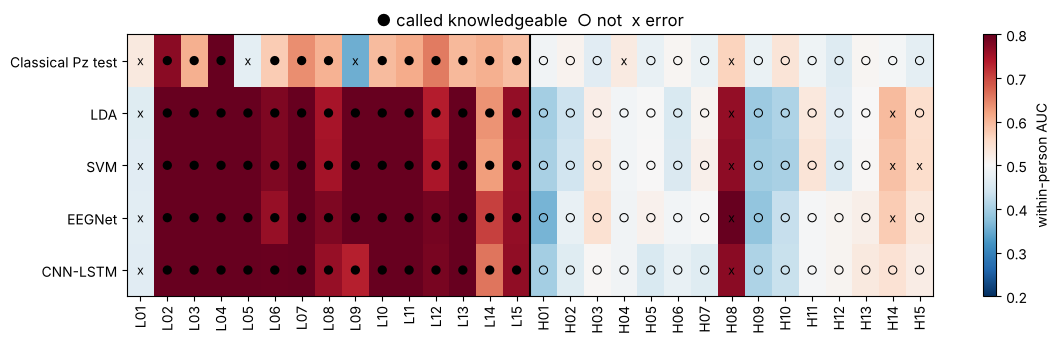

Classical Pz test  errors: ['H04', 'H08', 'L01', 'L05', 'L09']
LDA                errors: ['H08', 'H14', 'L01']
SVM                errors: ['H08', 'H14', 'H15', 'L01']
EEGNet             errors: ['H08', 'H14', 'L01']
CNN-LSTM           errors: ['H08', 'L01']


In [3]:
codes = [f"L{i:02d}" for i in range(1, 16)] + [f"H{i:02d}" for i in range(1, 16)]
A = np.array([[{p["code"]: p for p in r["persons"]}[c]["auc"] for c in codes] for r in R.values()])
D = np.array([[{p["code"]: p for p in r["persons"]}[c]["decision"] for c in codes] for r in R.values()])
truth = np.array([1] * 15 + [0] * 15)
fig, ax = plt.subplots(figsize=(13, 3.4)); im = ax.imshow(A, cmap="RdBu_r", vmin=.2, vmax=.8, aspect="auto")
for i in range(len(R)):
    for j in range(30):
        ax.text(j, i, "x" if D[i, j] != truth[j] else ("●" if D[i, j] else "○"), ha="center", va="center", fontsize=9)
ax.set_xticks(range(30)); ax.set_xticklabels(codes, rotation=90); ax.set_yticks(range(len(R))); ax.set_yticklabels(R.keys())
ax.axvline(14.5, c="k"); plt.colorbar(im, label="within-person AUC"); ax.set_title("● called knowledgeable  ○ not  x error"); plt.show()
for k, r in R.items(): print(f"{k:18s} errors:", [p["code"] for p in r["persons"] if p["decision"] != p["group"]])

In [4]:
correct = {k: 30 - sum(p["decision"] != p["group"] for p in r["persons"]) for k, r in R.items()}
print("correct person-level decisions out of 30:", correct)
print("gain over classical Pz test:", {k: v - correct["Classical Pz test"] for k, v in correct.items()})

correct person-level decisions out of 30: {'Classical Pz test': 25, 'LDA': 27, 'SVM': 26, 'EEGNet': 27, 'CNN-LSTM': 28}
gain over classical Pz test: {'Classical Pz test': 0, 'LDA': 2, 'SVM': 1, 'EEGNet': 2, 'CNN-LSTM': 3}


**Reading.** The trained models raise trial AUC from 0.62 to about 0.90 but add only one to three correct person decisions out of 30; all confidence intervals overlap. The errors follow people (L01, H08) more than algorithms.